#### Team members:
* Kevin Patel (kpatel2s)

In [1]:
### General imports
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
import torch.nn as nn
import torch.distributions as distributions
import torch.optim as optim

In [2]:
import random
import cv2
from collections import deque
import os
import matplotlib
import math
from IPython.display import clear_output
from tqdm import tqdm

In [3]:
# To install pygame
!pip install -q gymnasium[classic-control]


[notice] A new release of pip is available: 24.1 -> 24.3.1
[notice] To update, run: pip install --upgrade pip


In [4]:
def set_seed(seed=8):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(DEVICE)

cpu


# Visuomotor Policies

In this assignment, you will develop a simple visuomotor policy for solving the simple cart-pole problem. For this, you will use the [gymnasium](https://gymnasium.farama.org/) (which defines the cart-pole environment) as well as PyTorch for implementing and training neural network models.

## Policy Network Implementation [30 points]

In the cell below, implement the `LearningAgent` class that defines policy and/or value networks (depending on the reinforcement learning algorithm that you want to implement) and allows you to sample actions from the learned policy as well as perform network updates based on experiences.

Your network should be defined so that the $s \in S$ is an image of the cart-pole system and the action space is discrete - move left or move right.

Note: If it helps, you are free to incorporate existing implementations of reinforcement learning algorithms, for instance as provided in [Stable Baselines3](https://stable-baselines3.readthedocs.io/en/master/), in your solution.

In [5]:
# Define an agent that implements a deep reinforcement learning algorithm of your choice to solve an MDP.
# The class should:
# * define your policy / value networks
# * enable sample actions from the learned policy, and
# * enable network updates based on experiences
# You will need to update the function signatures so that you can pass appropriate parameters.


class LearningAgent(nn.Module):
    def __init__(self, action_space=2, replay_memory_size=50000):
        # YOUR CODE HERE
        super(LearningAgent, self).__init__()
        # Hyperparameters
        self.action_space = action_space
        self.learning_rate = 1e-4
        self.discount_factor = 0.90
        self.EPS = 1.0
        self.EPS_MIN = 0.05
        self.EPS_DECAY = 1000
        self.TAU = 0.005
        self.replay_memory_size = replay_memory_size       # size of replay memory
        self.target_update_freq = 100
        self.sample_size = 128            # size of the training data set sampled from the replay memory
        self.image_dim = 48

        self.memory = deque([], maxlen=self.replay_memory_size)  # Experience Replay Memory

        # Create policy and target network
        self.policy_net_dqn = self.DQNCNN(
            input_channels=1, out_actions=self.action_space).to(DEVICE)
        self.target_net_dqn = self.DQNCNN(
            input_channels=1, out_actions=self.action_space).to(DEVICE)
        # Sync target network with policy network
        self.target_net_dqn.load_state_dict(self.policy_net_dqn.state_dict())

        # Loss function
        self.loss_fn = nn.SmoothL1Loss()
        self.optimizer = torch.optim.AdamW(
            self.policy_net_dqn.parameters(), lr=self.learning_rate, amsgrad=True)

        self.update_count = 0  # Counter to manage target network updates

    def DQNCNN(self, input_channels, out_actions):
        self.conv_layers = nn.Sequential(
            nn.Conv2d(in_channels=input_channels, out_channels=32, kernel_size=3, stride=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=32, out_channels=64,
                      kernel_size=3, stride=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
#             nn.Conv2d(in_channels=64, out_channels=64,
#                       kernel_size=3, stride=1),
#             nn.ReLU(),
#             nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
        )

        with torch.no_grad():
            dummy_input = torch.rand(1, input_channels, self.image_dim, self.image_dim)
            conv_output = self.conv_layers(dummy_input)
            conv_output_size = conv_output.size(1)

        return nn.Sequential(
            self.conv_layers,
            nn.Linear(conv_output_size, 128),
            nn.ReLU(),
            nn.Linear(128, out_actions)
        )

    def sample_action(self, state):
        """Samples an action from the policy.
        """
        # YOUR CODE HERE
        if random.random() < self.EPS:  # Explore
            return random.randrange(self.action_space)
        else:  # Exploit
            state = torch.FloatTensor(state).unsqueeze(0).to(DEVICE)
            q_values = self.policy_net_dqn(state)
            return q_values.argmax().item()  # Action with highest Q-value

    def store_transition(self, state, action, reward, next_state, done):
        """Store a transition in the replay buffer."""
        self.memory.append((state, action, reward, next_state, done))

    def update(self):
        """Updates the network parameters.
        """
        # YOUR CODE HERE

        if len(self.memory) < self.sample_size:
            return

        # Sample a batch of transitions
        batch = random.sample(self.memory, self.sample_size)
        states, actions, rewards, next_states, dones = zip(*batch)

        states = torch.FloatTensor(np.array(states)).to(DEVICE)
        actions = torch.LongTensor(actions).unsqueeze(1).to(DEVICE)
        rewards = torch.FloatTensor(rewards).unsqueeze(1).to(DEVICE)
        dones = torch.FloatTensor(dones).unsqueeze(1).to(DEVICE)

        # Handle None values in next_states
        non_final_mask = torch.tensor(
            tuple(map(lambda s: s is not None, next_states)), device=DEVICE, dtype=torch.bool)
        
        # Create a tensor of non-final next states
        non_final_next_states = torch.cat([torch.FloatTensor(np.array(s)).unsqueeze(0) for s in next_states if s is not None]).to(DEVICE)

        # Compute Q values
        q_values = self.policy_net_dqn(states).gather(1, actions)

        # Compute target Q values using target network
        next_state_values = torch.zeros(self.sample_size, device=DEVICE)
        with torch.no_grad():
            next_state_values[non_final_mask] = self.target_net_dqn(non_final_next_states).max(1)[0]
        target_q_values = rewards + self.discount_factor * next_state_values.unsqueeze(1) * (1 - dones)

        # Compute loss
        loss = self.loss_fn(q_values, target_q_values)
        self.optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.policy_net_dqn.parameters(), 100)
        self.optimizer.step()

        target_net_state_dict = self.target_net_dqn.state_dict()
        policy_net_state_dict = self.policy_net_dqn.state_dict()
        for key in policy_net_state_dict:
            target_net_state_dict[key] = policy_net_state_dict[key] * \
                self.TAU + target_net_state_dict[key]*(1-self.TAU)
        self.target_net_dqn.load_state_dict(target_net_state_dict)

        # Update target network
#         if self.update_count % self.target_update_freq == 0:
#             self.target_net_dqn.load_state_dict(self.policy_net_dqn.state_dict())
#         self.update_count += 1

## Agent Training [40 points]

Now that your network is defined, implement the reinforcement learning loop for your agent in the cell below. This means that you need to collect experiences of the form $(s_t, a_t, s_{t+1}, r)$ so that you can update your policy network appropriately. How exactly you do the update will depend on the RL algorithm you use.

Plot the evolution of the return over the learning process to show that your agent is actually learning. Note, however, that, as reinforcement learning algorithms have randomness associated with them, the results will differ every time you execute the algorithm; thus, you should plot an average of the return (over multiple runs) instead of the return of a single run --- like on the plots shown [here](https://how-do-you-learn.readthedocs.io/en/latest/rl/reinforce.html).

Training:   0%|          | 0/300 [00:00<?, ?it/s]error: XDG_RUNTIME_DIR not set in the environment.
Episode 300 | Epsilon: 0.05 | Reward: 26.0 | Moving Avg: 27.42: 100%|██████████| 300/300 [1:44:39<00:00, 20.93s/it]
/tmp/ipykernel_458/3204082416.py:61: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at ../aten/src/ATen/native/ReduceOps.cpp:1808.)
  std_dev = durations_t[:i].std()
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Complete


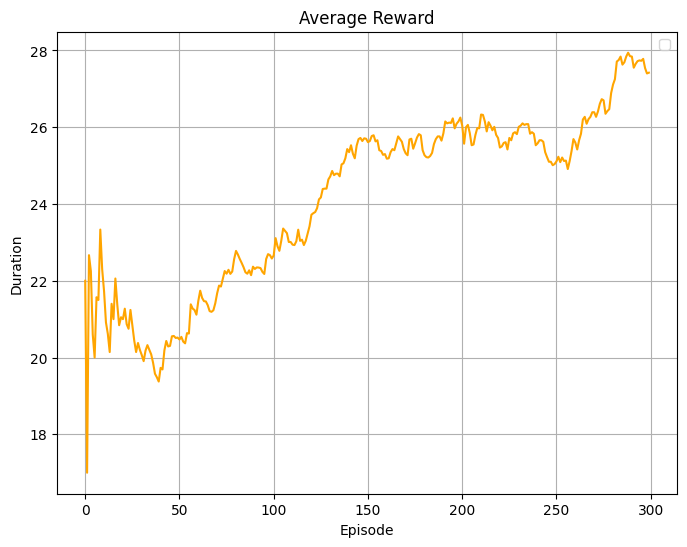

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [6]:
# creating the cart pole environment in a way that allows us to render the observation as an image
env = gym.make("CartPole-v1", render_mode='rgb_array')

### You can obtain an image of the current state of the system as follows:
###     current_img_state = env.render()

# YOUR CODE HERE

# set up matplotlib
is_ipython = 'inline' in matplotlib.get_backend()
if is_ipython:
    from IPython import display

# plt.ion()

# os.makedirs("models", exist_ok=True)
# Variable to track the best moving average reward
best_avg_reward = -float("inf")

agent = LearningAgent(action_space=env.action_space.n)

num_episodes = 300
moving_avg_window = 100

# Lists to store episode returns for plotting
all_episode_rewards = []
moving_avg_rewards = []
epsilons = []
best_episode = 0

def preprocess_frame(frame):
    """Converts the environment's RGB frame to a grayscale, resized image suitable for DQN."""
    gray_frame = cv2.cvtColor(frame, cv2.COLOR_RGB2GRAY)
    resized_frame = cv2.resize(
        gray_frame, (agent.image_dim, agent.image_dim), interpolation=cv2.INTER_LINEAR)
    normalized_frame = resized_frame / 255.0
    return np.expand_dims(normalized_frame, axis=0)


def plot_durations(show_result=False):
    # Plot episode durations and moving average in Figure 1
    plt.figure(figsize=(8, 6))
    plt.clf()

    durations_t = torch.tensor(all_episode_rewards, dtype=torch.float)
    if show_result:
        plt.title('Average Reward')
    else:
        plt.title('Training...')
    plt.xlabel('Episode')
    plt.ylabel('Duration')
    plt.grid(True)

    window_size = 100
    if len(durations_t) > 0:
        means = []
        std_devs = []
        for i in range(1, len(durations_t) + 1):
            if i < window_size:
                mean = durations_t[:i].mean()
                std_dev = durations_t[:i].std()
            else:
                mean = durations_t[i-window_size:i].mean()
                std_dev = durations_t[i-window_size:i].std()
            means.append(mean)
            std_devs.append(std_dev)

        means = torch.tensor(means)
        std_devs = torch.tensor(std_devs)

        plt.plot(means.numpy(), color="orange")

    plt.legend()
    plt.pause(0.01)

    if is_ipython:
        if not show_result:
            display.display(plt.gcf())
            display.clear_output(wait=True)
        else:
            display.display(plt.gcf())

progress_bar = tqdm(range(num_episodes), desc="Training", total=num_episodes)
            
for episode in progress_bar:
    state, info = env.reset()
    episode_reward = 0
    done = False

    while not done:
        # Get the image frame, preprocess it, and normalize
        frame = env.render()
        state = preprocess_frame(frame)

        # Sample action and interact with the environment
        action = agent.sample_action(state)
        next_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        next_frame = env.render()
        next_state = preprocess_frame(next_frame) if not done else None

        # Store transition in replay buffer
        agent.store_transition(state, action, reward, next_state, done)

        # Update network parameters
        agent.update()

        episode_reward += reward

    # Decay epsilon for epsilon-greedy policy
    agent.EPS = max(agent.EPS_MIN, agent.EPS_MIN + (agent.EPS -
                    agent.EPS_MIN) * math.exp(-1. * episode / agent.EPS_DECAY))

    # Store episode reward
    all_episode_rewards.append(episode_reward)

    epsilons.append(agent.EPS)

    # plot_durations(show_result=False)

    # Calculate moving average for smoothing
    if len(all_episode_rewards) >= moving_avg_window:
        moving_avg = np.mean(all_episode_rewards[-moving_avg_window:])
    else:
        moving_avg = np.mean(all_episode_rewards)
    moving_avg_rewards.append(moving_avg)

    # Check if current moving average is the best so far to save the model
    if moving_avg > best_avg_reward:
        best_avg_reward = moving_avg
        best_episode = episode
    #     torch.save(agent.policy_net_dqn.state_dict(), f"models/best_model.pth")
        # print(f"[INFO] New best model at episode {episode + 1} with average reward: {moving_avg:.2f}")

    # Print episode statistics
    # print(f"Episode: {episode + 1}, Epsilon: {agent.EPS:.2f}, Reward: {episode_reward}, Moving Average: {moving_avg:.2f}")
    progress_bar.set_description(
        f"Episode {episode + 1} | Epsilon: {agent.EPS:.2f} | Reward: {episode_reward} | Moving Avg: {moving_avg:.2f}"
    )

print('Complete')
plot_durations(show_result=True)
# plt.ioff()
plt.show()
env.close()

Observation:

Image data has a high-dimensional state space, meaning the model must interpret complex visual information to make decisions between just two actions (left and right). Learning an effective policy from such high-dimensional states requires more time and computational resources to converge. Despite experimenting with larger networks, more parameters, different learning rates, and other hyperparameters, the total episode reward remains low, showing little improvement. Additionally, due to the convolutional neural network (CNN) blocks needed for processing image data, the model demands far more computational resources.

Overall, using only a single image snapshot as the input state does not provide enough information for a DQN (deep Q-network) agent to effectively train an optimal policy for the CartPole environment.

## Combining Visual and Explicit State Information [30 points]

Modify your implementation of the policy network so that it takes both the image and the explicit state information of the system as separate inputs (thus turning the policy into a multimodal policy). Then, update the learning loop accordingly and verify that learning is indeed taking place.

In [ ]:
class DQNCNN_2(nn.Module):
    def __init__(self, input_channels, input_size, img_dim, out_actions):
        super().__init__()
        self.conv_layers = nn.Sequential(
            nn.Conv2d(in_channels=input_channels,
                      out_channels=32, kernel_size=3, stride=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=32, out_channels=64,
                      kernel_size=3, stride=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            # nn.Conv2d(in_channels=64, out_channels=64,
            #           kernel_size=3, stride=1),
            # nn.ReLU(),
            # nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
        )

        with torch.no_grad():
            dummy_input = torch.rand(
                1, input_channels, img_dim, img_dim)
            conv_output = self.conv_layers(dummy_input)
            conv_output_size = conv_output.size(1)

        self.fc_layers_1 = nn.Sequential(
            nn.Linear(conv_output_size, 64),
            nn.ReLU()
        )

        self.fc_layers_2 = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU()
        )

        self.fc_comb = nn.Sequential(
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, out_actions)
        )

    def forward(self, x):
        x_image = self.conv_layers(x[0])
        img_branch = self.fc_layers_1(x_image)
        proprio_branch = self.fc_layers_2(x[1])
        x = torch.cat([img_branch, proprio_branch], dim=1)
        x = self.fc_comb(x)
        return x

class UpdatedLearningAgent(nn.Module):
    def __init__(self, action_space=2, replay_memory_size=10000):
        super(UpdatedLearningAgent, self).__init__()
        # Hyperparameters
        self.action_space = action_space
        self.learning_rate = 1e-4
        self.discount_factor = 0.90
        self.EPS = 1.0
        self.EPS_MIN = 0.05
        self.EPS_DECAY = 1000
        self.TAU = 0.005
        self.replay_memory_size = replay_memory_size       # size of replay memory
        # size of the training data set sampled from the replay memory
        self.sample_size = 128
        self.image_dim = 48
        self.input_size = 4 # proprioceptive state size

        # Experience Replay Memory
        self.memory = deque([], maxlen=self.replay_memory_size)

        # Create policy and target network
        self.policy_net_dqn = DQNCNN_2(
            input_channels=1, input_size=self.input_size, img_dim=self.image_dim, out_actions=self.action_space).to(DEVICE)
        self.target_net_dqn = DQNCNN_2(
            input_channels=1, input_size=self.input_size, img_dim=self.image_dim, out_actions=self.action_space).to(DEVICE)
        # Sync target network with policy network
        self.target_net_dqn.load_state_dict(self.policy_net_dqn.state_dict())

        # Loss function
        self.loss_fn = nn.SmoothL1Loss()
        self.optimizer = torch.optim.AdamW(
            self.policy_net_dqn.parameters(), lr=self.learning_rate, amsgrad=True)

        self.update_count = 0  # Counter to manage target network updates

    def sample_action(self, state):
        """Samples an action from the policy.
        """
        # YOUR CODE HERE
        if random.random() < self.EPS:  # Explore
            return random.randrange(self.action_space)
        else:  # Exploit
            i_state = torch.FloatTensor(state[0]).unsqueeze(0).to(DEVICE)
            p_state = torch.FloatTensor(state[1]).unsqueeze(0).to(DEVICE)
            state = (i_state, p_state)
            q_values = self.policy_net_dqn(state)
            return q_values.argmax().item()  # Action with highest Q-value

    def store_transition(self, state, action, reward, next_state, done):
        """Store a transition in the replay buffer."""
        self.memory.append((state, action, reward, next_state, done))

    def update(self):
        """Updates the network parameters.
        """
        # YOUR CODE HERE

        if len(self.memory) < self.sample_size:
            return

        # Sample a batch of transitions
        batch = random.sample(self.memory, self.sample_size)
        states, actions, rewards, next_comb_states, dones = zip(*batch)

        img_states = torch.FloatTensor(np.array(list(map(lambda x: x[0], states)))).to(DEVICE)
        proprio_states = torch.FloatTensor(np.array(list(map(lambda x: x[1], states)))).to(DEVICE)
        states = (img_states, proprio_states)
        # states = torch.FloatTensor(np.array(states)).to(DEVICE)

        actions = torch.LongTensor(actions).unsqueeze(1).to(DEVICE)
        rewards = torch.FloatTensor(rewards).unsqueeze(1).to(DEVICE)
        dones = torch.FloatTensor(dones).unsqueeze(1).to(DEVICE)

        # Handle None values in next_states
        non_final_mask = torch.tensor(
            tuple(map(lambda s: s[0] is not None, next_comb_states)), device=DEVICE, dtype=torch.bool)

        # Create a tensor of non-final next states
        non_final_next_states_img = torch.cat([torch.FloatTensor(s[0]).unsqueeze(0) for s in next_comb_states if s[0] is not None]).to(DEVICE)

        non_final_next_states_proprio = torch.cat([torch.FloatTensor(np.array(s[1])).unsqueeze(
            0) for s in next_comb_states if s[1] is not None]).to(DEVICE)

        if len(non_final_next_states_img) != len(non_final_next_states_proprio):
            print("Image and proprioceptive states are not of the same length")

        non_final_next_states = (non_final_next_states_img, non_final_next_states_proprio)

        # Compute Q values
        q_values = self.policy_net_dqn(states).gather(1, actions)

        # Compute target Q values using target network
        next_state_values = torch.zeros(self.sample_size, device=DEVICE)
        with torch.no_grad():
            try:
                next_state_values[non_final_mask] = self.target_net_dqn(non_final_next_states).max(1)[0]
            except:
                next_state_values[non_final_mask] = self.target_net_dqn(
                    non_final_next_states).max(1)[0].detach()
        target_q_values = rewards + self.discount_factor * \
            next_state_values.unsqueeze(1) * (1 - dones)

        # Compute loss
        loss = self.loss_fn(q_values, target_q_values)
        self.optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.policy_net_dqn.parameters(), 100)
        self.optimizer.step()

        target_net_state_dict = self.target_net_dqn.state_dict()
        policy_net_state_dict = self.policy_net_dqn.state_dict()
        for key in policy_net_state_dict:
            target_net_state_dict[key] = policy_net_state_dict[key] * \
                self.TAU + target_net_state_dict[key]*(1-self.TAU)
        self.target_net_dqn.load_state_dict(target_net_state_dict)

In [ ]:
# creating the cart pole environment in a way that allows us to render the observation as an image
env = gym.make("CartPole-v1", render_mode='rgb_array')

# You can obtain an image of the current state of the system as follows:
# current_img_state = env.render()

# YOUR CODE HERE

# set up matplotlib
is_ipython = 'inline' in matplotlib.get_backend()
if is_ipython:
    from IPython import display

# plt.ion()

# Variable to track the best moving average reward
best_avg_reward = -float("inf")

agent = UpdatedLearningAgent(action_space=env.action_space.n)

num_episodes = 200
moving_avg_window = 100

# Lists to store episode returns for plotting
all_episode_rewards = []
moving_avg_rewards = []
epsilons = []
best_episode = 0

def preprocess_frame(frame):
    """Converts the environment's RGB frame to a grayscale, resized image suitable for DQN."""
    gray_frame = cv2.cvtColor(frame, cv2.COLOR_RGB2GRAY)
    resized_frame = cv2.resize(
        gray_frame, (agent.image_dim, agent.image_dim), interpolation=cv2.INTER_LINEAR)
    normalized_frame = resized_frame / 255.0
    return np.expand_dims(normalized_frame, axis=0)


def plot_durations(show_result=False):
    # Plot episode durations and moving average in Figure 1
    plt.figure(figsize=(8, 6))
    plt.clf()

    durations_t = torch.tensor(all_episode_rewards, dtype=torch.float)
    if show_result:
        plt.title('Result')
    else:
        plt.title('Training...')
    plt.xlabel('Episode')
    plt.ylabel('Duration')
    plt.grid(True)
    
    window_size = 100
    if len(durations_t) > 0:
        means = []
        std_devs = []
        for i in range(1, len(durations_t) + 1):
            if i < window_size:
                mean = durations_t[:i].mean()
                std_dev = durations_t[:i].std()
            else:
                mean = durations_t[i-window_size:i].mean()
                std_dev = durations_t[i-window_size:i].std()
            means.append(mean)
            std_devs.append(std_dev)

        means = torch.tensor(means)
        std_devs = torch.tensor(std_devs)

        plt.plot(means.numpy(), label="Moving Average", color="orange")

    plt.legend()
    plt.pause(0.01)
    
    if is_ipython:
        if not show_result:
            display.display(plt.gcf())
            display.clear_output(wait=True)
        else:
            display.display(plt.gcf())
        
for episode in range(num_episodes):
    proprio_state, info = env.reset()
    episode_reward = 0
    done = False

    while not done:
        # Get the image frame, preprocess it, and normalize
        frame = env.render()
        img_state = preprocess_frame(frame)

        state_comb = [img_state, proprio_state]

        # Sample action and interact with the environment
        action = agent.sample_action(state_comb)
        proprio_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        next_frame = env.render()
        next_img_state = preprocess_frame(next_frame) if not done else None
        proprio_state = proprio_state if not done else None

        next_state_comb = [next_img_state, proprio_state]

        # Store transition in replay buffer
        agent.store_transition(
            state_comb, action, reward, next_state_comb, done)

        # Update network parameters
        agent.update()

        episode_reward += reward

    # Decay epsilon for epsilon-greedy policy
    agent.EPS = max(agent.EPS_MIN, agent.EPS_MIN + (agent.EPS -
                    agent.EPS_MIN) * math.exp(-1. * episode / agent.EPS_DECAY))
    # agent.EPS = max(agent.EPS_MIN, agent.EPS - 0.0005)

    # Store episode reward
    all_episode_rewards.append(episode_reward)
    
    epsilons.append(agent.EPS)

#     plot_durations(show_result=False)

    # Calculate moving average for smoothing
    if len(all_episode_rewards) >= moving_avg_window:
        moving_avg = np.mean(all_episode_rewards[-moving_avg_window:])
    else:
        moving_avg = np.mean(all_episode_rewards)
    moving_avg_rewards.append(moving_avg)

    # Check if current moving average is the best so far to save the model
    if moving_avg > best_avg_reward:
        best_avg_reward = moving_avg
        best_episode = episode
        # torch.save(agent.policy_net_dqn.state_dict(), f"models/best_model.pth")
        # print(
        #     f"[INFO] New best model at episode {episode + 1} with average reward: {moving_avg:.2f}")

    # Print episode statistics
    print(
        f"Episode: {episode + 1}, Epsilon: {agent.EPS:.2f}, Reward: {episode_reward}, Moving Average: {moving_avg:.2f}")


# print(f"Best moving average reward: {best_avg_reward} at episode {best_episode}")

print('Complete')
plot_durations(show_result=True)
# plt.ioff()
plt.show()
env.close()

#### NOTE: 
- As training the multi-modal network took significantly longer on JupyterHub, I used a GPU-based system for faster testing and experimentation. 
- The code remained unchanged, and the agent's policy training graph output is shown below.
- Also the trained model is uploaded at `models/multi_modal_output_weights.pt` for reference
- Although it's trained only 200 episodes, the output is clearly better than the single modality

### Multi-modal policy training plot:

![image](models/multi_modal_output.png)  

Has the second modality changed the behaviour of the agent? Discuss the observations from your evaluation here.

Yes, adding a second modality with proprioceptive states (velocity, position, angle, and angular velocity) significantly improves the agent's ability to learn an optimal policy. For the DQN, adding a branch to process these internal states, merging its features with those extracted from the image input, and then feeding them into a fully connected layer enabled the model to perform far better than when using only the image state as input. The proprioceptive states provide low-dimensional, relevant information, which in this simple environment is sufficient for learning effective features that guide the agent’s actions. The advantage of this second modality likely arises from the fact that mapping four low-dimensional states to two actions is computationally simpler than working with the high-dimensional inputs of an image modality.

Additionally, I trained a DQN agent using only proprioceptive states as input, and it alone yielded much better results compared to the image-only modality. When combining both modalities (internal states and image data), the agent performed even better than either single modality alone, achieving higher rewards (means balancing the pole for a longer duration).

In conclusion, providing both image and proprioceptive states as inputs in the CartPole environment helped the agent learn a better policy.
